<a href="https://colab.research.google.com/github/trishnanika/Image-Processing-Project/blob/main/demo_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import json
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_PATH = "/content/drive/MyDrive/CSE428_Project"
CHECKPOINT_DIR = os.path.join(PROJECT_PATH, "checkpoints_v2")
DEMO_ASSETS_PATH = os.path.join(PROJECT_PATH, "demo_assets_v2")

IMG_SIZE = 128

with open(os.path.join(DEMO_ASSETS_PATH, "breed_to_idx.json")) as f:
    breed_to_idx = json.load(f)
idx_to_breed = {v: k for k, v in breed_to_idx.items()}

print("Device:", device)
print("Number of breeds:", len(breed_to_idx))

Mounted at /content/drive
Device: cpu
Number of breeds: 37


In [ ]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import tarfile
import shutil
import time
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# ============================================================
# CELL 18: U-NET DOUBLE CONVOLUTION BLOCK
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

print("DoubleConv block defined.")

# ============================================================
# CELL 19: CLASSIFIER HEAD WITH EXTRA CONV LAYERS
# ============================================================

class ClassifierHeadV2(nn.Module):
    """
    Adds 2 convolutional layers on the bottleneck feature map
    BEFORE global average pooling, to let the classifier learn
    its own spatial features rather than relying purely on the
    segmentation-shared bottleneck.
    """

    def __init__(self, in_channels=1024, num_classes=37):
        super().__init__()

        # Extra convolutional layers before pooling
        self.conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(in_channels)

        self.conv2 = nn.Conv2d(in_channels, 512, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(512)

        self.relu = nn.ReLU(inplace=True)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc1 = nn.Linear(512, 256)
        self.bn_fc1 = nn.BatchNorm1d(256)
        self.dropout = nn.Dropout(p=0.4)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):

        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.bn_fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

print("ClassifierHeadV2 (with extra conv layers) defined.")

# ============================================================
# CELL 21: BASE MULTI-TASK U-NET (BINARY SEGMENTATION HEAD)
# ============================================================

class MultiTaskUNet(nn.Module):

    def __init__(self, num_breed_classes=37):
        super().__init__()

        # ---- Encoder ----
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(kernel_size=2)

        # ---- Bottleneck ----
        self.bottleneck = DoubleConv(512, 1024)

        # ---- Classification head ----
        self.classifier = ClassifierHeadV2(in_channels=1024, num_classes=num_breed_classes)

        # ---- Decoder ----
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # ---- Segmentation output: single channel (binary) ----
        self.final = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        classification_output = self.classifier(b)

        d4 = self.up4(b); d4 = torch.cat([d4, e4], dim=1); d4 = self.dec4(d4)
        d3 = self.up3(d4); d3 = torch.cat([d3, e3], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); d2 = torch.cat([d2, e2], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); d1 = torch.cat([d1, e1], dim=1); d1 = self.dec1(d1)

        # Output shape: (B, 1, H, W) -> squeeze to (B, H, W)
        segmentation_output = self.final(d1).squeeze(1)

        return segmentation_output, classification_output

print("Base Multi-Task U-Net (1-channel segmentation output) defined.")

# ============================================================
# CELL 24: ATTENTION GATE MODULE
# ============================================================

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        attention = self.relu(g1 + x1)
        attention = self.psi(attention)
        return x * attention

print("Attention Gate module defined.")

# ============================================================
# CELL 25: ATTENTION MULTI-TASK U-NET
# ============================================================

class AttentionMultiTaskUNet(nn.Module):

    def __init__(self, num_breed_classes=37):
        super().__init__()

        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(kernel_size=2)

        self.bottleneck = DoubleConv(512, 1024)

        self.classifier = ClassifierHeadV2(in_channels=1024, num_classes=num_breed_classes)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.att4 = AttentionGate(F_g=512, F_l=512, F_int=256)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.att3 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att2 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att1 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        classification_output = self.classifier(b)

        d4 = self.up4(b); e4a = self.att4(g=d4, x=e4); d4 = torch.cat([d4, e4a], dim=1); d4 = self.dec4(d4)
        d3 = self.up3(d4); e3a = self.att3(g=d3, x=e3); d3 = torch.cat([d3, e3a], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); e2a = self.att2(g=d2, x=e2); d2 = torch.cat([d2, e2a], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); e1a = self.att1(g=d1, x=e1); d1 = torch.cat([d1, e1a], dim=1); d1 = self.dec1(d1)

        segmentation_output = self.final(d1).squeeze(1)

        return segmentation_output, classification_output

print("Attention Multi-Task U-Net (1-channel segmentation output) defined.")

DoubleConv block defined.
ClassifierHeadV2 (with extra conv layers) defined.
Base Multi-Task U-Net (1-channel segmentation output) defined.
Attention Gate module defined.
Attention Multi-Task U-Net (1-channel segmentation output) defined.


In [ ]:
multitask_model = MultiTaskUNet(num_breed_classes=37).to(device)
multitask_model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "best_base_multitask_unet.pth"), map_location=device))
multitask_model.eval()

attention_model = AttentionMultiTaskUNet(num_breed_classes=37).to(device)
attention_model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "best_attention_multitask_unet.pth"), map_location=device))
attention_model.eval()

print("Both models loaded and ready.")

Both models loaded and ready.


In [ ]:
def get_breed_name(image_path):
    filename = os.path.splitext(os.path.basename(image_path))[0]
    return filename.rsplit("_", 1)[0]


def run_demo_prediction(model, image_path, model_name="Model", trimap_path=None, threshold=0.5):

    original_image = Image.open(image_path).convert("RGB")
    resized_image = original_image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    image_tensor = torch.tensor(np.array(resized_image), dtype=torch.float32).permute(2, 0, 1) / 255.0

    with torch.no_grad():
        seg_output, cls_output = model(image_tensor.unsqueeze(0).to(device))

    probs = torch.sigmoid(seg_output)
    pred_mask = (probs.squeeze(0) > threshold).long().cpu()
    pred_label = torch.argmax(cls_output, dim=1).item()
    pred_breed = idx_to_breed[pred_label]

    img_np = np.array(resized_image)

    if trimap_path is None:
        candidate = os.path.join(os.path.dirname(image_path), "..", "annotations", "trimaps",
                                  os.path.splitext(os.path.basename(image_path))[0] + ".png")
        if os.path.exists(candidate):
            trimap_path = candidate

    if trimap_path is not None and os.path.exists(trimap_path):
        true_mask_raw = np.array(Image.open(trimap_path))
        true_mask = (true_mask_raw != 2).astype(np.uint8)
        true_mask_resized = np.array(
            Image.fromarray(true_mask).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST)
        )

        true_breed = get_breed_name(image_path)

        tp = ((pred_mask.numpy() == 1) & (true_mask_resized == 1)).sum()
        fp = ((pred_mask.numpy() == 1) & (true_mask_resized == 0)).sum()
        fn = ((pred_mask.numpy() == 0) & (true_mask_resized == 1)).sum()
        iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0

        print(f"[{model_name}]")
        print(f'Original class - "{true_breed}"')
        print(f'Predicted class - "{pred_breed}"')
        print(f"IoU - {iou*100:.1f}%")

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(img_np); axes[0].set_title("Original Image"); axes[0].axis("off")
        axes[1].imshow(img_np); axes[1].imshow(true_mask_resized, cmap="Greens", alpha=0.4)
        axes[1].set_title("Image + True Mask Overlay"); axes[1].axis("off")
        axes[2].imshow(img_np); axes[2].imshow(pred_mask, cmap="Greens", alpha=0.4)
        axes[2].set_title("Image + Predicted Mask Overlay"); axes[2].axis("off")
        plt.suptitle(model_name)
        plt.show()

    else:
        print(f"[{model_name}]")
        print(f'Predicted class - "{pred_breed}"')
        print("(No ground-truth mask found - showing prediction only)")

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img_np); axes[0].set_title("Original Image"); axes[0].axis("off")
        axes[1].imshow(img_np); axes[1].imshow(pred_mask, cmap="Greens", alpha=0.4)
        axes[1].set_title("Image + Predicted Mask Overlay"); axes[1].axis("off")
        plt.suptitle(model_name)
        plt.show()

print("Demo function ready.")

Demo function ready.


Saving american_bulldog_131.jpg to american_bulldog_131.jpg
[Base U-Net]
Predicted class - "american_bulldog"
(No ground-truth mask found - showing prediction only)


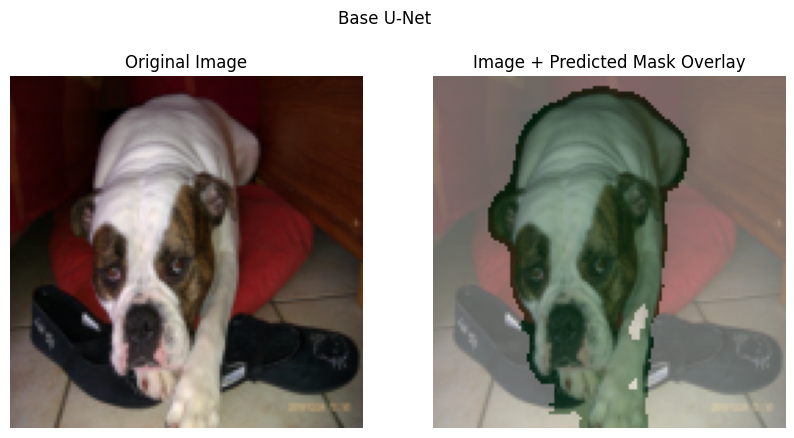

[Attention U-Net]
Predicted class - "american_bulldog"
(No ground-truth mask found - showing prediction only)


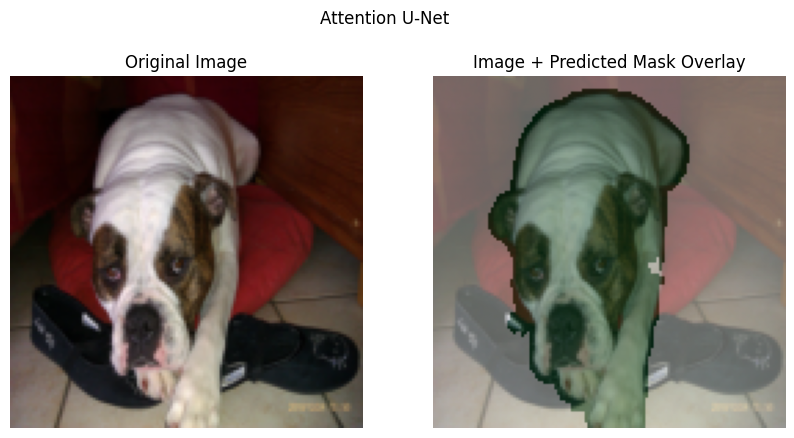

In [ ]:
from google.colab import files
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

run_demo_prediction(multitask_model, image_path, model_name="Base U-Net")
run_demo_prediction(attention_model, image_path, model_name="Attention U-Net")

In [ ]:
# ============================================================
# CELL 6: TEST WITH GROUND-TRUTH MASK (UPLOAD IMAGE + TRIMAP)
# ============================================================

from google.colab import files

print("Step 1: Upload the ORIGINAL IMAGE (e.g. Abyssinian_12.jpg)")
uploaded_image = files.upload()
test_image_path = list(uploaded_image.keys())[0]

print("\nStep 2: Upload the MATCHING TRIMAP (e.g. Abyssinian_12.png)")
uploaded_trimap = files.upload()
test_trimap_path = list(uploaded_trimap.keys())[0]

print("\n--- Running predictions ---\n")

run_demo_prediction(multitask_model, test_image_path, model_name="Base U-Net", trimap_path=test_trimap_path)
run_demo_prediction(attention_model, test_image_path, model_name="Attention U-Net", trimap_path=test_trimap_path)

Step 1: Upload the ORIGINAL IMAGE (e.g. Abyssinian_12.jpg)


Saving pomerian dog.jpg to pomerian dog (1).jpg

Step 2: Upload the MATCHING TRIMAP (e.g. Abyssinian_12.png)


KeyboardInterrupt: 

In [ ]:
# ============================================================
# CELL 7: FINAL READINESS CHECK
# ============================================================

checks_passed = True

# Check 1: models loaded
try:
    _ = next(multitask_model.parameters())
    _ = next(attention_model.parameters())
    print("✓ Both models are loaded in memory.")
except NameError:
    print("✗ Models not loaded. Re-run Cells 1-3.")
    checks_passed = False

# Check 2: breed mapping loaded
try:
    print(f"✓ Breed mapping loaded ({len(breed_to_idx)} breeds).")
except NameError:
    print("✗ breed_to_idx not loaded. Re-run Cell 1.")
    checks_passed = False

# Check 3: GPU active
print(f"✓ Device: {device}")

# Check 4: demo function ready
try:
    _ = run_demo_prediction
    print("✓ Demo function is defined.")
except NameError:
    print("✗ Demo function missing. Re-run Cell 4.")
    checks_passed = False

print("\n" + ("READY FOR DEMO ✓" if checks_passed else "NOT READY — fix the items marked ✗ above"))

✗ Models not loaded. Re-run Cells 1-3.
✗ breed_to_idx not loaded. Re-run Cell 1.


NameError: name 'device' is not defined